# 25 · A2A: serve an agent to another agent
Level L4 · Part 4 · core · ~30 min · builds on 19, 22

## Goal
Expose a LangGraph agent to other agents over A2A, the agent-to-agent protocol. The agent publishes a card at a known address, accepts a
task as a message, runs its graph, and returns the result as an artifact with a task state. The graph here looks up orders in code, so the
lesson makes no model call: the protocol is the subject.

## Why it matters
MCP (lessons 22 to 24) connects an agent to tools. A2A connects an agent to another agent. The other agent may belong to another team, run on
another machine, and know things your agent does not. Without a protocol, each pair of agents needs its own API, its own auth and its own
error handling.

| Without A2A | With A2A |
|---|---|
| Each pair of agents needs a custom API | Every agent publishes a card and speaks the same messages |
| The caller guesses what the other agent accepts | The card lists the skills and their inputs |
| A long job has no status between request and answer | A task has states the caller can read |

**What it makes easy:** an agent you did not build can be used by yours, through a published card and a task. **When you don't need it:** one
agent, one process, or a plain function call inside one program.

## The idea
An A2A agent has a **card** (who it is and what it does), a **task** (one piece of work, with an id), and **states** the task moves through.
The protocol names eight states: submitted, working, input-required, completed, failed, canceled, rejected and auth-required. The caller sends
a message; the server creates a task, runs the agent, and returns the task with its **artifacts** (the results). The transport here is
**JSON-RPC** (a request and response format carried over HTTP) on localhost.

## Picture

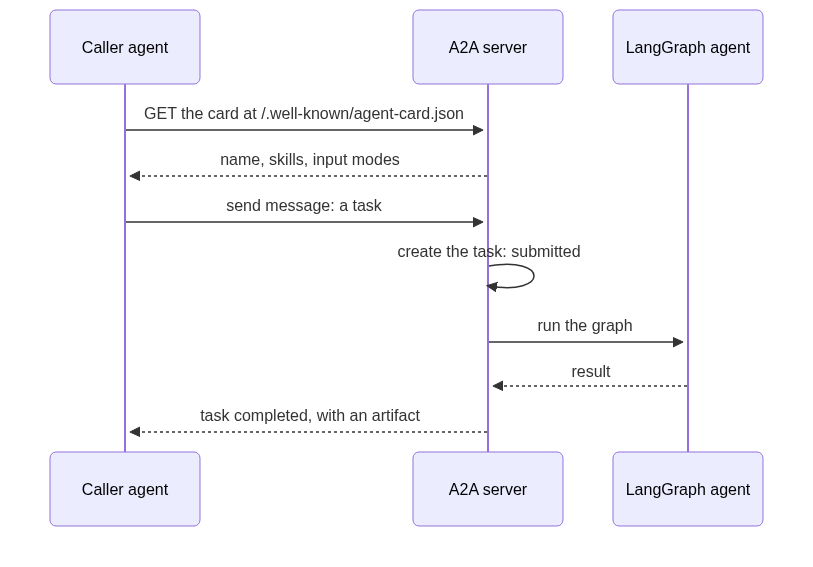

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py, a2a_server.py and tut_env.py live there

from graph_view import show_mermaid  # graph_view.py is this course's drawing helper: show_mermaid draws Mermaid text, show_graph draws a compiled graph

show_mermaid("""
sequenceDiagram
  participant C as Caller agent
  participant S as A2A server
  participant G as LangGraph agent
  C->>S: GET the card at /.well-known/agent-card.json
  S-->>C: name, skills, input modes
  C->>S: send message: a task
  S->>S: create the task: submitted
  S->>G: run the graph
  G-->>S: result
  S-->>C: task completed, with an artifact
""")

## Step by step

**Step 1 · the agent: a LangGraph graph with two code nodes (no call).** The graph reads the question, looks up the order, and writes
the answer. Each node does one job, so the graph is the agent, and the protocol wraps it. The order rows are the fictional ones from the
earlier lessons.

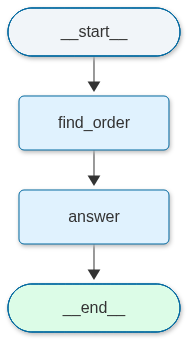

Order 1003 is lost, 9 days late.


In [2]:
import json
from pathlib import Path
from typing import TypedDict

from langgraph.graph import END, START, StateGraph

ORDERS = json.loads((Path("../../../data") / "support_eval.json").read_text())["world"]["orders"]


class OrderState(TypedDict):
    question: str
    order_id: str
    answer: str


def find_order(state: OrderState) -> dict:
    digits = [w.strip("?.,") for w in state["question"].split() if w.strip("?.,").isdigit()]
    return {"order_id": digits[0] if digits else ""}


def answer(state: OrderState) -> dict:
    row = ORDERS.get(state["order_id"])
    if row is None:
        return {"answer": "I need the four-digit order number from your confirmation email."}
    return {"answer": f"Order {state['order_id']} is {row['status']}, {row['days_late']} days late."}


orders_graph = StateGraph(OrderState)
orders_graph.add_node("find_order", find_order)
orders_graph.add_node("answer", answer)
orders_graph.add_edge(START, "find_order").add_edge("find_order", "answer").add_edge("answer", END)
orders_app = orders_graph.compile()
from graph_view import show_graph
show_graph(orders_app)
print(orders_app.invoke({"question": "Where is order 1003?", "order_id": "", "answer": ""})["answer"])

**Step 2 · the executor: the bridge from the protocol to the graph (no call).** The A2A server calls `execute` for each task. The executor takes
the message text, runs the graph, and reports the state changes through a task updater: working, then an artifact, then completed. If the graph
raises, the task is marked failed instead of hanging.

In [3]:
from a2a.helpers import get_message_text, new_task_from_user_message, new_text_part
from a2a.server.agent_execution import AgentExecutor
from a2a.server.tasks import TaskUpdater


class OrdersExecutor(AgentExecutor):
    async def execute(self, context, event_queue):
        task = context.current_task
        if not task:
            task = new_task_from_user_message(context.message)
            await event_queue.enqueue_event(task)  # the task exists before any status update
        updater = TaskUpdater(event_queue, task.id, task.context_id)
        await updater.start_work()
        try:
            result = orders_app.invoke({"question": get_message_text(context.message), "order_id": "", "answer": ""})
        except Exception as error:
            await updater.failed()
            return
        await updater.add_artifact([new_text_part(result["answer"])], name="answer")
        await updater.complete()

    async def cancel(self, context, event_queue):
        raise NotImplementedError("this agent cannot cancel a task")

**Step 3 · serve the agent and read its card (no call).** `a2a_server.py` is this topic's helper for the protocol lessons. `serve` starts an
A2A agent on a free localhost port, in a background thread, and returns its address. `stop` shuts it down, and `send_text` sends it one
message (Step 4). The card is published at `/.well-known/agent-card.json`. The cell fetches it the way any caller would.

In [4]:
import httpx
from a2a_server import serve, stop, send_text

base, server = serve("orders-agent", "Answers order status questions for Brightside Outfitters.",
                     [("order_status", "Order status", "The status and days late of one order.")], OrdersExecutor())
async with httpx.AsyncClient() as http:
    card = (await http.get(base + "/.well-known/agent-card.json")).json()
print("served at:", base)
print("card name:", card["name"], "· skills:", [s["id"] for s in card["skills"]])

served at: http://127.0.0.1:39467
card name: orders-agent · skills: ['order_status']


**Step 4 · send a task and read its states (no call).** The caller sends one message. The server answers with the task, and the cell prints
its final state by name and its artifact. Here the client gets a single event: the completed task.

In [5]:
from a2a.types import a2a_pb2

events = await send_text(base, "Where is order 1003?")
print("events:", len(events))
for event in events:
    if event.HasField("task"):
        print("task state:", a2a_pb2.TaskState.Name(event.task.status.state))
        for artifact in event.task.artifacts:
            print("artifact:", artifact.name, "→", artifact.parts[0].text)

events: 1
task state: TASK_STATE_COMPLETED
artifact: answer → Order 1003 is lost, 9 days late.


**Step 5 · a task the agent cannot finish (no call).** A message with no order number makes the graph ask for one. The task still completes, with
the answer that asks for the number: a reply the caller can act on, not an error.

In [6]:
events = await send_text(base, "Where is my parcel?")
for event in events:
    if event.HasField("task"):
        print("task state:", a2a_pb2.TaskState.Name(event.task.status.state), "→", event.task.artifacts[0].parts[0].text)
stop(server)  # the server is local to this lesson: stop it so the port is free

task state: TASK_STATE_COMPLETED → I need the four-digit order number from your confirmation email.


## At work
- Teams publish an agent's card next to its code, and version it with the agent. A caller pins the version it was tested against → lesson 26
  (A2A discovery) and lesson 27 (registry and delegation).
- A task that runs for minutes is a state the caller can poll or stream. Teams show the state to the user rather than a spinner → lesson 28
  (task lifecycle).
- An agent that accepts tasks from other companies is an attack surface. Each task is authenticated, and its input is treated as data → lesson 34.

## What just happened
- The card named `orders-agent` with one skill, `order_status`: that is what another agent reads before it sends a task.
- Order 1003 gave one event, a task in state `TASK_STATE_COMPLETED`, with the artifact "Order 1003 is lost, 9 days late."
- With no order number, the task still ended in `TASK_STATE_COMPLETED`, and its artifact asked for the four-digit number.
- The graph did the work; the executor only translated each step into a task state.

## Common mistakes
Each mistake below runs its own small agent and prints the real error, then the fix.

**1. A status update before the task exists.** The task must be created and enqueued first, as Step 2 does. Otherwise the SDK refuses the
update, and the caller gets an error.

In [7]:
import logging
logging.disable(logging.CRITICAL)  # the SDK logs a full traceback; this cell prints only the first line of the error


class EarlyUpdate(AgentExecutor):
    async def execute(self, context, event_queue):
        task = new_task_from_user_message(context.message)  # created, but never enqueued
        updater = TaskUpdater(event_queue, task.id, task.context_id)
        await updater.start_work()  # a status update for a task the queue has not seen

    async def cancel(self, context, event_queue):
        raise NotImplementedError("this agent cannot cancel a task")


base, server = serve("early", "Demo of a mistake.", [("demo", "Demo", "a demo skill")], EarlyUpdate())
try:
    await send_text(base, "hello")
except Exception as error:
    print(type(error).__name__, "→", str(error).splitlines()[0])
stop(server)
logging.disable(logging.NOTSET)

InvalidAgentResponseError → Agent should enqueue Task before TaskStatusUpdateEvent event


**Fix:** enqueue the task first, as in Step 2 (`await event_queue.enqueue_event(task)`), then send the status update.

**2. An error that escapes the graph.** If the graph raises and the executor does not catch it, the caller gets an RPC error, not a task with
a final state. Catch the error and mark the task failed, so the caller sees the end.

In [8]:
logging.disable(logging.CRITICAL)


class UncaughtError(AgentExecutor):
    async def execute(self, context, event_queue):
        task = new_task_from_user_message(context.message)
        await event_queue.enqueue_event(task)
        updater = TaskUpdater(event_queue, task.id, task.context_id)
        await updater.start_work()
        raise ValueError("graph broke")  # stands in for a graph that raises

    async def cancel(self, context, event_queue):
        raise NotImplementedError("this agent cannot cancel a task")


base, server = serve("uncaught", "Demo of a mistake.", [("demo", "Demo", "a demo skill")], UncaughtError())
try:
    await send_text(base, "hello")
except Exception as error:
    print(type(error).__name__, "→", str(error).splitlines()[0])
stop(server)
logging.disable(logging.NOTSET)

InternalError → graph broke


**Fix:** wrap the graph call in `try` and call `await updater.failed()` in the `except`, as Step 2 does. The caller then receives a task in
state `TASK_STATE_FAILED` (not an error).

**3. Sending without `await`.** `send_text` is a coroutine. Without `await` you get a coroutine object, not the events, and the loop over
it fails.

In [9]:
base, server = serve("orders-agent", "Demo of a mistake.", [("order_status", "Order status", "status of one order")], OrdersExecutor())
pending = send_text(base, "Where is order 1003?")  # missing await
try:
    for event in pending:
        pass
except TypeError as error:
    print(type(error).__name__, "→", str(error).splitlines()[0])
stop(server)

TypeError → 'coroutine' object is not iterable


**Fix:** write `events = await send_text(base, "Where is order 1003?")`, as Step 4 does. Inside a notebook cell `await` works at the top level.

## Try it
Write `final_state(events)` that returns the name of the last task state in `events` (for example `TASK_STATE_COMPLETED`), or `None` when there is none.
No model call is needed. Test it on the `events` from Step 5.

In [10]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [11]:
def final_state(events) -> str | None:
    states = [a2a_pb2.TaskState.Name(e.task.status.state) for e in events if e.HasField("task")]
    return states[-1] if states else None


print(final_state(events))  # TASK_STATE_COMPLETED

TASK_STATE_COMPLETED


## Key terms
- **Agent card** — the JSON description an A2A agent publishes at `/.well-known/agent-card.json`: its name, skills and endpoint.
- **Task** — one piece of work sent to an A2A agent, with an id; it moves through named states.
- **Task state** — where a task is now, such as submitted, working, completed or failed.
- **Artifact** — a result a task returns, here the answer text.
- **Executor** — your class that the A2A server calls for each task; it runs your agent and reports state changes.
- **JSON-RPC** — a request and response format (method, params, result) that A2A sends over HTTP.

## Recap
- An A2A agent publishes a card and runs tasks. A task has an id and moves through named states.
- The executor bridges the protocol to the graph: it creates the task, runs the graph, and reports each state.
- A task the agent cannot finish still ends in a state the caller can read.

**Interview:** "How would you let another team's agent ask yours a question?" Strong answer: "Publish a card with the skills and their inputs, accept
the request as a task, run my agent inside an executor, and return the result with a final state. The caller reads the card and the state."